In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# Figures for Nir — batch 2

In [2]:
import json
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from src.bt import FeatureBT

SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#d6d5d1",
    "axes.labelcolor": INK, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 10,
    "savefig.bbox": "tight", "savefig.dpi": 200,
})
FIGDIR = "figs/figs4nir2"
os.makedirs(FIGDIR, exist_ok=True)

BRANDS = ["ASUS", "Apple", "Dell", "HP", "Lenovo"]
SCREEN, RAM = ["13-inch", "14-inch", "16-inch"], ["4GB", "8GB", "16GB"]
FEATS = ["brand", "screen", "ram"]
LEVELS = {"brand": BRANDS, "screen": SCREEN, "ram": RAM}
LAPTOPS = [(b, s, r) for b in BRANDS for s in SCREEN for r in RAM]
IDX = {l: i for i, l in enumerate(LAPTOPS)}
FEATURE_COLOR = {"brand": "#6aa83f", "screen": "#c75f8b", "ram": "#4c8fd4"}   # same muted colours as model_summary
MODELS = [("qwen", "32"), ("qwen", "72")]


def runs(folder, model, frame=None):
    """Complete runs (9900 rows) of one model in one folder -> list of (config, scores)."""
    out = []
    for r in sorted(os.listdir(folder)):
        cf, sc = f"{folder}/{r}/config.json", f"{folder}/{r}/scores.csv"
        if not (os.path.isfile(cf) and os.path.isfile(sc)):
            continue
        c = json.load(open(cf))
        if (c["model_family"], str(c["model_size"])) != model or (frame and c["frame"]["name"] != frame):
            continue
        d = pd.read_csv(sc)
        if len(d) == 9900:
            out.append((c, d))
    return out


def slug(user):
    return user.replace('"', "in").replace(" ", "_")


## A — persona effect on feature weights (student vs editor)

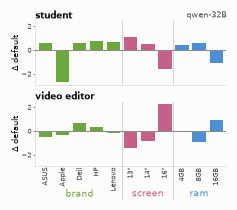

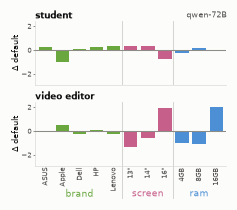

In [3]:
PERSONAS = ["student_only", "editor"]
PERSONA_LABEL = {"student_only": "student", "editor": "video editor"}
LV = [(f, l) for f in FEATS for l in LEVELS[f]]
LABEL = {l: l.replace("-inch", '"') for _, l in LV}


def weights(c_d):
    return FeatureBT(r2_warn=None).fit(c_d[1]).weights_


DELTA = {}
for m in MODELS:
    base = [x for x in runs("data/laptops_robustness", m, "shopping") if x[0]["constraints"] == {}]
    assert len(base) == 1
    w0 = weights(base[0])
    for p in PERSONAS:
        pr = [x for x in runs("data/laptops_persona", m, p) if x[0]["constraints"] == {}]
        assert len(pr) == 1, (m, p, len(pr))
        w1 = weights(pr[0])
        DELTA[(m, p)] = pd.Series({l: w1[f][l] - w0[f][l] for f, l in LV})


GROUP_NAME = {"brand": "brand", "screen": "screen", "ram": "ram"}


YLIM_A = (min(d.min() for d in DELTA.values()) * 1.1, max(d.max() for d in DELTA.values()) * 1.1)   # shared by both models


def fig_a(m):
    fig, axes = plt.subplots(2, 1, figsize=(2, 1.75), sharex=True, sharey=True)
    x = np.arange(len(LV))
    for ax, p in zip(axes, PERSONAS):
        ax.bar(x, DELTA[(m, p)].values, 0.78, color=[FEATURE_COLOR[f] for f, _ in LV], zorder=2)
        ax.axhline(0, color="#8d8b85", lw=0.7, zorder=3)
        ax.set_title(PERSONA_LABEL[p], loc="left", fontsize=6, fontweight="bold", pad=1.5)
        ax.set_ylabel("Δ default", fontsize=5, labelpad=1)
        ax.set_ylim(*YLIM_A)
        ax.set_yticks([-2, 0, 2])
        ax.tick_params(axis="y", labelsize=4.5, length=1.5, width=0.4, pad=1, colors=INK_MUTED)
        ax.tick_params(axis="x", length=0, pad=1)
        ax.spines["left"].set_linewidth(0.4)
        ax.spines["bottom"].set_linewidth(0.4)
        ax.set_xlim(-0.6, len(LV) - 0.4)
    axes[0].text(1, 1.02, f"{m[0]}-{m[1]}B", transform=axes[0].transAxes, ha="right", va="bottom", fontsize=5,
                 color=INK_MUTED)
    axes[1].set_xticks(x, [LABEL[l] for _, l in LV], rotation=90, fontsize=4.5, color=INK_MUTED)
    fig.tight_layout(h_pad=0.4, pad=0.15, rect=(0, 0.035, 1, 1))
    for k in (5, 8):
        for ax in axes:
            ax.axvline(k - 0.5, color="#c9c8c3", lw=0.5, zorder=1)
        axes[1].plot([k - 0.5, k - 0.5], [0, -0.5], transform=axes[1].get_xaxis_transform(), color="#c9c8c3",
                     lw=0.5, clip_on=False)
    for f, (a, b) in zip(FEATS, [(0, 4), (5, 7), (8, 10)]):
        axes[1].text((a + b) / 2, -0.43, GROUP_NAME[f], transform=axes[1].get_xaxis_transform(), ha="center",
                     va="center", fontsize=6, color=FEATURE_COLOR[f])
    fig.savefig(os.path.join(FIGDIR, f"A_persona_delta_{m[0]}-{m[1]}B.png"), facecolor=SURFACE, dpi=400)
    fig.savefig(os.path.join(FIGDIR, f"A_persona_delta_{m[0]}-{m[1]}B.pdf"), facecolor=SURFACE)
    plt.show()


for m in MODELS:
    fig_a(m)


## B — contract paths (qwen-32B)

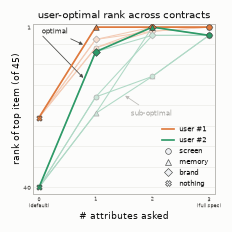

In [4]:
USERS = {
    'Dell 14" 8GB': {"brand": "Dell", "screen": "14-inch", "ram": "8GB"},
    'Apple 14" 8GB': {"brand": "Apple", "screen": "14-inch", "ram": "8GB"},
    'Dell 14" 4GB': {"brand": "Dell", "screen": "14-inch", "ram": "4GB"},
}
USER_COLOR = {'Apple 14" 8GB': "#3b6fc4", 'Dell 14" 8GB': "#df7a3e", 'Dell 14" 4GB': "#2e9a68"}
MARK = {"screen": "o", "ram": "^", "brand": "D"}
EMPTY = "X"                                                   # k = 0: the empty contract
MARK_NAME = {"screen": "screen", "ram": "memory", "brand": "brand"}
PATHS = list(itertools.permutations(FEATS))
MODEL_B = ("qwen", "32")
FRAME_COL = "#bdbcb8"


def borda(d):
    T_ = sorted(d.template_idx.unique())
    M = np.full((len(T_), 45, 45), np.nan)
    ia = [IDX[(a, b, c)] for a, b, c in zip(d.a_brand, d.a_screen, d.a_ram)]
    ib = [IDX[(a, b, c)] for a, b, c in zip(d.b_brand, d.b_screen, d.b_ram)]
    M[[T_.index(t) for t in d.template_idx], ia, ib] = d.score_a.values - d.score_b.values
    D = (M - M.transpose(0, 2, 1)) / 2
    return pd.Series(np.nanmean(D.mean(0), axis=1), index=LAPTOPS)


BORDA = {}                      # (model, frozenset of (feature, level)) -> Borda score of every laptop
for m in MODELS:
    for c, d in runs("data/laptops_robustness", m, "shopping"):
        key = (m, frozenset(c["constraints"].items()))
        assert key not in BORDA, f"two complete runs for {key}"
        BORDA[key] = borda(d)


def step(m, target, p, k):
    """(rank of the target, its lead over the best other laptop) after the first k features of path p;
    lead < 0 = how far behind the top. (nan, nan) if the run is missing."""
    key = (m, frozenset((f, target[f]) for f in p[:k]))
    if key not in BORDA:
        return np.nan, np.nan
    b, tgt = BORDA[key], tuple(target[f] for f in FEATS)
    return b.rank(ascending=False, method="min")[tgt], b[tgt] - b.drop(tgt).max()


def path_points(m, target, p):
    return [step(m, target, p, k)[0] for k in range(4)]


def complete(m, u):
    """All k = 1 and k = 2 runs exist, so the paths can be compared."""
    return all(np.isfinite(path_points(m, USERS[u], p)[1:3]).all() for p in PATHS)


def best_path(m, u):
    """The ONE optimal path: closest to the top, soonest. Compared step by step: rank at k = 1, then the
    lead at k = 1, then rank and lead at k = 2."""
    def score(p):
        (r1, l1), (r2, l2) = step(m, USERS[u], p, 1), step(m, USERS[u], p, 2)
        return (r1, -l1, r2, -l2)
    return min(PATHS, key=score)


def pale(color, t=0.62):
    c, w = np.array(to_rgb(color)), np.ones(3)
    return tuple(c + (w - c) * t)


def panel(ax, layers, arrows, ymax=None, sc=1.0):
    """layers = [(model, user), ...] drawn on one axis, each in its user's colour with its own optimal path.
    sc scales every size (text, lines, markers, arrows) for a smaller figure."""
    data = []
    for m, u in layers:
        pts = {p: np.array(path_points(m, USERS[u], p), dtype=float) for p in PATHS}
        data.append((m, u, pts, best_path(m, u)))
    ymax = ymax or max(np.nanmax(y) for *_, pts, _ in data for y in pts.values())
    for m, u, pts, best in data:                                   # all pale lines first ...
        col = USER_COLOR[u]
        for p in PATHS:
            if p == best:
                continue
            ys = pts[p]; ok = np.isfinite(ys)
            ax.plot(np.arange(4)[ok], ys[ok], color=pale(col), lw=1.5 * sc, zorder=2, solid_capstyle="round")
            for k in (1, 2, 3):
                if np.isfinite(ys[k]):
                    ax.scatter(k, ys[k], marker=MARK[p[k - 1]], s=48 * sc ** 2, zorder=3, color=pale(col, 0.75),
                               edgecolor=pale("#3a3a38", 0.6), lw=0.8 * sc)
    for m, u, pts, best in data:                                   # ... then every optimal path on top
        col, ys = USER_COLOR[u], pts[best]
        ok = np.isfinite(ys)
        ax.plot(np.arange(4)[ok], ys[ok], color=col, lw=2.4 * sc, zorder=4, solid_capstyle="round")
        for k in (1, 2, 3):
            if np.isfinite(ys[k]):
                ax.scatter(k, ys[k], marker=MARK[best[k - 1]], s=60 * sc ** 2, zorder=6, color=col, edgecolor="#3a3a38", lw=0.8 * sc)
        ax.scatter(0, ys[0], marker=EMPTY, s=60 * sc ** 2, zorder=6, color=col, edgecolor="#3a3a38", lw=0.8 * sc)   # k = 0: nothing asked
    if arrows:
        for i, (m, u, pts, best) in enumerate(data):
            yb = pts[best]
            ax.annotate("optimal" if i == 0 else "", xy=(0.8, yb[0] + 0.8 * (yb[1] - yb[0])),
                        xytext=(0.05, 1 + 0.05 * (ymax - 1)), fontsize=10 * sc, color="#2b2b29", ha="left", va="bottom",
                        arrowprops=dict(arrowstyle="-|>", color="#4a4a47", lw=1.1 * sc, shrinkA=2 * sc, shrinkB=2 * sc,
                                        mutation_scale=10 * sc))
        # the worst pale path over all layers, pointed at mid-way between k = 1 and k = 2 (away from the bold lines)
        yw = max((pts[p] for *_, pts, best in data for p in PATHS if p != best and np.isfinite(pts[p][2])),
                 key=lambda y: y[1] + y[2])
        ym = (yw[1] + yw[2]) / 2
        ax.annotate("sub-optimal", xy=(1.5, ym), xytext=(1.62, ym + 0.2 * (ymax - ym)),
                    fontsize=10 * sc, color="#a9a8a4", ha="left", va="center",
                    arrowprops=dict(arrowstyle="-|>", color="#bdbcb8", lw=1.1 * sc, shrinkA=4 * sc, shrinkB=2 * sc,
                                    mutation_scale=10 * sc))
    ax.set_xlim(-0.1, 3.1)
    ax.set_ylim(ymax + 0.04 * ymax, 0.2)
    ax.set_yticks([1, int(ymax)] if ymax < 30 else [1, 10, 20, 30, 40][: int(ymax // 10) + 1])
    ax.set_xticks(range(4), ["0\n(default)", "1", "2", "3\n(full spec)"], fontsize=6.5 * sc, color=INK_MUTED)
    ax.tick_params(axis="x", length=0, pad=4 * sc)
    ax.tick_params(axis="y", length=0, labelsize=9 * sc, pad=3 * sc)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color(FRAME_COL); sp.set_linewidth(1.4 * sc)


def draw_grid(users=list(USERS), models=MODELS, fname=None):
    """Rows = models, columns = users; one (user, model) per panel. A panel whose runs are missing says so."""
    fig, axes = plt.subplots(len(models), len(users), figsize=(3.6 * len(users), 3.8 * len(models)), squeeze=False)
    first = True
    for i, m in enumerate(models):
        for j, u in enumerate(users):
            ax = axes[i, j]
            ax.set_title(f"User #{j + 1}  ·  {m[0]}-{m[1]}B", fontsize=11, pad=6)
            if not complete(m, u):
                ax.text(0.5, 0.5, "runs missing", transform=ax.transAxes, ha="center", va="center", color=INK_MUTED)
                ax.set_xticks([]); ax.set_yticks([])
                for sp in ax.spines.values():
                    sp.set_visible(True); sp.set_color("#e4e3df")
                continue
            panel(ax, [(m, u)], arrows=first)
            first = False
    for ax in axes[-1]:
        ax.set_xlabel("# attributes asked", fontsize=11)
    for ax in axes[:, 0]:
        ax.set_ylabel("rank of top item (of 45)", fontsize=11)
    hu = [plt.Line2D([], [], color=USER_COLOR[u], lw=2.4, label=f"User #{j + 1}") for j, u in enumerate(users)]
    hm = [plt.Line2D([], [], marker=MARK[f], ls="", ms=8, color="#eef0f3", markeredgecolor="#3a3a38", mew=0.8,
                     label=MARK_NAME[f]) for f in ("screen", "ram", "brand")]
    hm.append(plt.Line2D([], [], marker=EMPTY, ls="", ms=8, color="#eef0f3", markeredgecolor="#3a3a38", mew=0.8, label="nothing"))
    fig.legend(handles=hu + hm, loc="upper center", ncol=len(hu + hm), frameon=False, fontsize=10.5,
               bbox_to_anchor=(0.5, 1.0))
    fig.suptitle("user utility across contracts", fontsize=15, y=1.045)
    fig.tight_layout(rect=(0, 0, 1, 0.965))
    if fname:
        fig.savefig(os.path.join(FIGDIR, fname), facecolor=SURFACE)
    plt.show()




UNUM = {u: i + 1 for i, u in enumerate(USERS)}                  # User #1 = Dell 14" 8GB, #2 = Apple, #3 = Dell 4GB
Q32, Q72 = ("qwen", "32"), ("qwen", "72")
U1, U2, U3 = list(USERS)
PAIRS = [[(Q32, U1), (Q32, U2)], [(Q32, U1), (Q32, U3)], [(Q72, U1), (Q32, U2)], [(Q72, U1), (Q32, U3)]]


def draw_pairs(pairs=PAIRS, fname=None):
    """Two (model, user) layers per panel, one panel per pair, the same y scale everywhere."""
    ymax = max(np.nanmax(path_points(m, USERS[u], p)) for pr in pairs for m, u in pr for p in PATHS)
    fig, axes = plt.subplots(2, 2, figsize=(8.4, 8.4), sharey=True, squeeze=False)
    for i, (ax, pr) in enumerate(zip(axes.flat, pairs)):
        panel(ax, pr, arrows=(i == 0), ymax=ymax)
        ax.set_title("  +  ".join(f"User #{UNUM[u]} ({m[0]}-{m[1]}B)" for m, u in pr), fontsize=10.5, pad=6)
    for ax in axes[-1]:
        ax.set_xlabel("# attributes asked", fontsize=11)
    for ax in axes[:, 0]:
        ax.set_ylabel("rank of top item (of 45)", fontsize=11)
    hu = [plt.Line2D([], [], color=USER_COLOR[u], lw=2.4, label=f"User #{UNUM[u]}") for u in USERS]
    hm = [plt.Line2D([], [], marker=MARK[f], ls="", ms=8, color="#eef0f3", markeredgecolor="#3a3a38", mew=0.8,
                     label=MARK_NAME[f]) for f in ("screen", "ram", "brand")]
    hm.append(plt.Line2D([], [], marker=EMPTY, ls="", ms=8, color="#eef0f3", markeredgecolor="#3a3a38", mew=0.8, label="nothing"))
    fig.legend(handles=hu + hm, loc="upper center", ncol=6, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle("user-optimal rank across contracts", fontsize=15, y=1.045)
    fig.tight_layout(rect=(0, 0, 1, 0.965))
    if fname:
        fig.savefig(os.path.join(FIGDIR, fname), facecolor=SURFACE)
    plt.show()




def draw_final(layers, labels, fname=None, size=2.0):
    """One axis in the reference design: several (model, user) layers, both arrows, legend inside.
    size = figure width = height in inches; every size inside scales with it (designed at 4.3 in)."""
    sc = size / 4.3
    fig, ax = plt.subplots(figsize=(size, size))
    panel(ax, layers, arrows=True, sc=sc)
    ymax = int(max(np.nanmax(path_points(m, USERS[u], p)) for m, u in layers for p in PATHS))
    ax.set_yticks([1, ymax])
    for y in range(5, ymax + 1, 5):                                  # light guide lines every 5 ranks
        ax.axhline(y, color="#e8e7e3", lw=0.8 * sc, zorder=0)
    ax.set_xlabel("# attributes asked", fontsize=12 * sc, labelpad=3 * sc)
    ax.set_ylabel("rank of top item (of 45)", fontsize=12 * sc, labelpad=3 * sc)
    ax.set_title("user-optimal rank across contracts", fontsize=14 * sc, pad=8 * sc)
    hu = [plt.Line2D([], [], color=USER_COLOR[u], lw=2.4 * sc, label=lab) for (m, u), lab in zip(layers, labels)]
    hm = [plt.Line2D([], [], marker=MARK[f], ls="", ms=8 * sc, color="#eef0f3", markeredgecolor="#3a3a38", mew=0.8 * sc,
                     label=MARK_NAME[f]) for f in ("screen", "ram", "brand")]
    hm.append(plt.Line2D([], [], marker=EMPTY, ls="", ms=8 * sc, color="#eef0f3", markeredgecolor="#3a3a38", mew=0.8 * sc,
                         label="nothing"))
    ax.legend(handles=hu + hm, frameon=False, fontsize=10 * sc, loc="lower right", handlelength=1.6, labelspacing=0.45)
    fig.tight_layout(pad=0.3)
    if fname:
        fig.savefig(os.path.join(FIGDIR, fname + ".png"), facecolor=SURFACE, dpi=400)
        fig.savefig(os.path.join(FIGDIR, fname + ".pdf"), facecolor=SURFACE)
    plt.show()


draw_final([(Q72, U1), (Q32, U3)], ["user #1", "user #2"], fname="B_contract_paths_final")


## C — preferences across simple domains (coherence, sharpness, agreement)

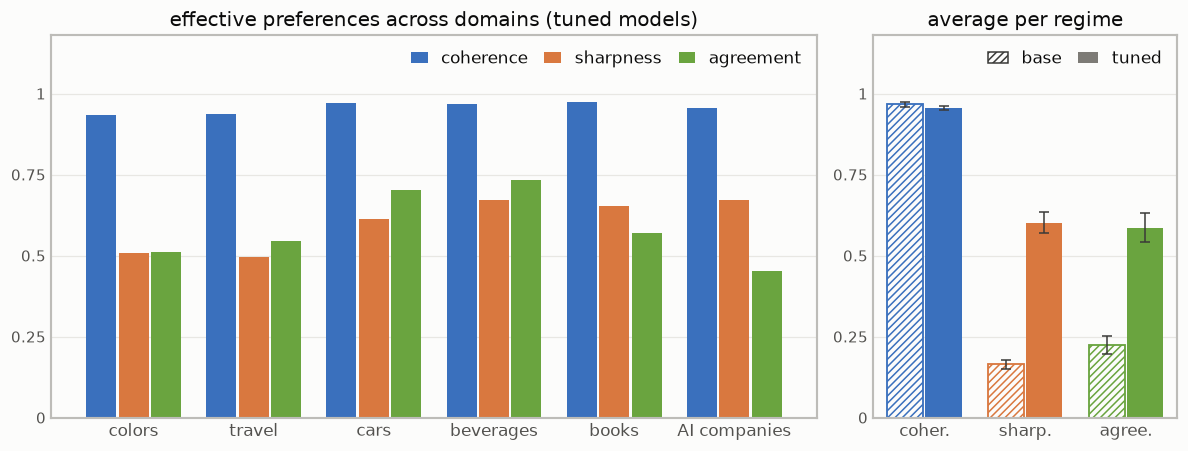

In [5]:
from scipy.stats import spearmanr, rankdata
from src.pref_models import fit_BT_soft

DOMS = ["colors", "travel_destinations", "cars", "beverages", "literature_genres", "ai_companies"]
DLABEL = {"colors": "colors", "travel_destinations": "travel", "cars": "cars", "beverages": "beverages",
          "literature_genres": "books", "ai_companies": "AI companies"}
SD_SIZES = {"qwen": ["0.5", "7", "32", "72"], "gemma": ["1", "4", "12", "27"], "olmo": ["1", "7", "13", "32"]}
SD_MODELS = [(f + v, s) for v in ("", "-pt") for f in SD_SIZES for s in SD_SIZES[f]]      # 12 tuned, then 12 base
MCOL = {"coherence": "#3a70bd", "sharpness": "#d9783f", "agreement": "#6aa43f"}


def sd_run(model, dom):
    """M[t, i, j] = margin with item i in slot 1, and the items, for one simple-domains run."""
    for r in sorted(os.listdir("data/simple_domains")):
        cf, sc = f"data/simple_domains/{r}/config.json", f"data/simple_domains/{r}/scores.csv"
        if not (os.path.isfile(cf) and os.path.isfile(sc)):
            continue
        c = json.load(open(cf))
        if (c["model_family"], str(c["model_size"]), c["alternatives"]) == (*model, dom):
            d = pd.read_csv(sc)
            items = sorted(set(d.a_item) | set(d.b_item))
            ix = {x: i for i, x in enumerate(items)}
            T_ = sorted(d.template_idx.unique())
            M = np.full((len(T_), len(items), len(items)), np.nan)
            M[[T_.index(t) for t in d.template_idx], d.a_item.map(ix), d.b_item.map(ix)] = d.score_a - d.score_b
            return M, items
    raise FileNotFoundError((model, dom))


def kendall_w(R):
    m, n = R.shape
    return 12 * ((R.sum(0) - m * (n + 1) / 2) ** 2).sum() / (m ** 2 * (n ** 3 - n))


rows, BORDA_SD = [], {}
for m in SD_MODELS:
    for dom in DOMS:
        M, items = sd_run(m, dom)
        n = len(items)
        D = (M - M.transpose(0, 2, 1)) / 2                       # position-corrected margin, per template
        off = ~np.eye(n, dtype=bool)
        borda = pd.Series(np.array([D[t][off].reshape(n, n - 1).mean(1) for t in range(len(D))]).mean(0), index=items)
        BORDA_SD[(m, dom)] = borda
        df = pd.DataFrame({"item_a": [items[i] for i in np.nonzero(off)[0]] * len(M),
                           "item_b": [items[j] for j in np.nonzero(off)[1]] * len(M),
                           "score_a": np.concatenate([M[t][off] for t in range(len(M))]), "score_b": 0.0})
        bt = fit_BT_soft(df, items)[0].set_index("Item").BT_Score[items]
        iu = np.triu_indices(n, 1)
        rows.append({"model": m, "regime": "base" if m[0].endswith("-pt") else "tuned", "domain": dom,
                     "coherence": spearmanr(bt, borda[items])[0],
                     "sharpness": np.tanh(np.abs(D[:, iu[0], iu[1]]) / 2).mean()})   # intrinsic: position-free
SDT = pd.DataFrame(rows)

DOMSUM = {}
for reg in ("tuned", "base"):
    ms = [m for m in SD_MODELS if m[0].endswith("-pt") == (reg == "base")]
    T = SDT[SDT.regime == reg].groupby("domain")[["coherence", "sharpness"]].mean().loc[DOMS]
    T["agreement"] = [kendall_w(np.array([rankdata(-BORDA_SD[(m, d)].sort_index().values) for m in ms])) for d in DOMS]
    DOMSUM[reg] = T


def frame_c(ax):
    ax.set_ylim(0, 1.18)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0", "0.25", "0.5", "0.75", "1"])
    ax.grid(True, axis="y", color="#e8e7e3", lw=0.8, zorder=0)
    ax.tick_params(length=0, labelsize=10)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color("#bdbcb8"); sp.set_linewidth(1.4)


def fig_c(fname="C_domain_summary"):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(4 + 1.15 * len(DOMS), 4.2),
                                 gridspec_kw={"width_ratios": [0.42 * len(DOMS), 1]})
    x = np.arange(len(DOMS))
    for j, lab in enumerate(MCOL):
        a1.bar(x + (j - 1) * 0.27, DOMSUM["tuned"][lab].clip(lower=0), 0.25, color=MCOL[lab], label=lab, zorder=2)
    frame_c(a1)
    a1.set_xticks(x, [DLABEL[d] for d in DOMS], fontsize=11)
    a1.legend(frameon=False, ncol=3, loc="upper right", fontsize=11, handlelength=1, columnspacing=1)
    a1.set_title("effective preferences across domains (tuned models)", fontsize=13)
    for i, lab in enumerate(MCOL):
        for j, reg in enumerate(("base", "tuned")):
            v = DOMSUM[reg][lab]
            a2.bar(i + (j - 0.5) * 0.38, v.mean(), 0.36, yerr=v.std(ddof=1) / np.sqrt(len(v)), capsize=3,
                   error_kw={"lw": 1, "ecolor": "#3a3a38"}, zorder=2, color=SURFACE if reg == "base" else MCOL[lab],
                   edgecolor=MCOL[lab], hatch="/////" if reg == "base" else None, lw=1.2 if reg == "base" else 0)
    frame_c(a2)
    a2.set_xticks(range(3), ["coher.", "sharp.", "agree."], fontsize=11)
    a2.legend(handles=[plt.Rectangle((0, 0), 1, 1, facecolor=SURFACE, edgecolor="#3a3a38", hatch="/////", label="base"),
                       plt.Rectangle((0, 0), 1, 1, facecolor="#7d7b76", label="tuned")],
              frameon=False, fontsize=11, loc="upper right", ncol=2, handlelength=1.2, columnspacing=1)
    a2.set_title("average per regime", fontsize=13)
    fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, fname + ".png"), facecolor=SURFACE)
    fig.savefig(os.path.join(FIGDIR, fname + ".pdf"), facecolor=SURFACE)
    plt.show()


fig_c()